## Objectives

In this lab you will

- implement the softmax function in a numerically stable way;
- understand the softmax regression model and see that it contains logistic regression as a special case;
- implement the cross-entropy cost and its gradient, and train the model with gradient descent;
- use scikit-learn on a small example and on the iris flowers, and evaluate a model with the confusion matrix;
- compare softmax regression with the one-vs-rest approach.

## Tools

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

np.set_printoptions(precision=3, suppress=True)   # print arrays with 3 decimals, no e-notation

## Multiclass classification

Many questions have more than two possible answers: which digit is in an image, which species a flower belongs to, which blood type a patient has. In **multiclass classification**, every example belongs to exactly one of $K \ge 3$ classes, $y \in \{1, \dots, K\}$. The model must give $K$ probabilities that form a probability distribution:
$$
P(y = k \mid \mathbf x) \ge 0 \quad\text{for } k = 1, \dots, K,
\qquad
\sum_{k=1}^{K} P(y = k \mid \mathbf x) = 1,
$$
and it predicts the class with the largest probability, $\hat y = \arg\max_k P(y = k \mid \mathbf x)$.

::: {.callout-warning title="Class labels in code"}
The lecture numbers the classes $1, \dots, K$. scikit-learn and NumPy number them $0, \dots, K - 1$, so class $k$ of the formulas is the label `k - 1` in the code, just as $x^{(i)}$ is `x[i-1]`.
:::

## The softmax function

The **softmax** function turns $K$ real numbers $z_1, \dots, z_K$, the **scores**, into a probability distribution:
$$
\operatorname{softmax}(\mathbf z)_k = \frac{e^{z_k}}{\sum_{l=1}^{K} e^{z_l}}, \qquad k = 1, \dots, K.
$$
Every output is positive, the outputs add up to one, and the largest score gets the largest probability: softmax is a "soft" version of picking the maximum.

A direct implementation fails for large scores, because $e^{1000}$ overflows:

In [2]:
def softmax_naive(z):
    return np.exp(z) / np.sum(np.exp(z))

print(softmax_naive(np.array([1000.0, 999.0, 998.0])))      # NumPy warns

[nan nan nan]


/tmp/ipykernel_1385/1419547078.py:2: RuntimeWarning: overflow encountered in exp
  return np.exp(z) / np.sum(np.exp(z))
/tmp/ipykernel_1385/1419547078.py:2: RuntimeWarning: invalid value encountered in divide
  return np.exp(z) / np.sum(np.exp(z))


Since $e^{z_k - c}/\sum_l e^{z_l - c} = e^{z_k}/\sum_l e^{z_l}$ for any constant $c$, we may subtract the largest score first. Then the largest exponent is $e^0 = 1$, and nothing overflows. Our function works row by row on a matrix of scores, one row per example:

In [3]:
def softmax(Z):
    """Row-wise softmax of the scores Z (shape (m, K)); every row of the result sums to 1."""
    Z = Z - Z.max(axis=1, keepdims=True)      # subtract the largest score of each row
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

Z_test = np.array([[2.0, 1.0, 0.1], [1.0, 1.0, 1.0], [1000.0, 999.0, 998.0]])
P_test = softmax(Z_test)
print(P_test)
print(f"row sums: {P_test.sum(axis=1)}")

[[0.659 0.242 0.099]
 [0.333 0.333 0.333]
 [0.665 0.245 0.09 ]]
row sums: [1. 1. 1.]


`keepdims=True` keeps the reduced axis with length $1$, so `Z.max(axis=1, keepdims=True)` has shape `(m, 1)` and broadcasts over the $K$ columns.

## The softmax regression model

Each class $k$ gets its own linear score, with its own weights $\mathbf w_k$ and bias $b_k$:
$$
z_k = \mathbf w_k\cdot\mathbf x + b_k,
\qquad
P(y = k \mid \mathbf x) = \operatorname{softmax}(\mathbf z)_k = \frac{e^{\mathbf w_k\cdot\mathbf x + b_k}}{\sum_{l=1}^{K} e^{\mathbf w_l\cdot\mathbf x + b_l}} .
$$
The weight vectors form the rows of a matrix $\mathbf W$ of shape $(K, n)$, and the biases a vector $\mathbf b$ of length $K$: in total $K(n + 1)$ parameters. For all $m$ examples at once, the scores are $\mathbf Z = \mathbf X\mathbf W^{\top} + \mathbf b$, of shape $(m, K)$.

In [4]:
def predict_proba(X, W, b):
    """Class probabilities of a softmax regression model, shape (m, K)."""
    return softmax(X @ W.T + b)

### Two classes: back to logistic regression

With $K = 2$ classes, called $0$ and $1$, dividing the numerator and the denominator by $e^{z_1}$ gives
$$
P(y = 1 \mid \mathbf x) = \frac{e^{z_1}}{e^{z_0} + e^{z_1}} = \frac{1}{1 + e^{-(z_1 - z_0)}} = g\big((\mathbf w_1 - \mathbf w_0)\cdot\mathbf x + (b_1 - b_0)\big),
$$
the logistic regression model of Part 3a with $\mathbf w = \mathbf w_1 - \mathbf w_0$ and $b = b_1 - b_0$. Softmax regression therefore **generalises** logistic regression. It also shows that only the **differences** between the scores matter: adding the same vector to every $\mathbf w_k$ (and the same number to every $b_k$) does not change any probability.

In [5]:
z0, z1 = 0.3, 1.8
print(f"softmax: {softmax(np.array([[z0, z1]]))[0, 1]:.4f}, sigmoid(z1 - z0): {1 / (1 + np.exp(-(z1 - z0))):.4f}")

softmax: 0.8176, sigmoid(z1 - z0): 0.8176


## A small example with three classes

We start with the six examples from the lecture, two per class. For more than two classes, scikit-learn's `LogisticRegression` uses the softmax model automatically.

In [6]:
X_toy = np.array([[0.5, 1.5], [1, 1.2], [1.5, 1.3], [3, 0.5], [2, 4], [1, 2.4]])
y_toy = np.array([0, 0, 1, 1, 2, 2])
K = 3

toy_model = LogisticRegression().fit(X_toy, y_toy)
print(f"predicted classes: {toy_model.predict(X_toy)}")
print(f"probabilities of the first two examples:\n{toy_model.predict_proba(X_toy[:2])}")
print(f"coef_ = W, shape {toy_model.coef_.shape}:\n{toy_model.coef_}")
print(f"intercept_ = b, shape {toy_model.intercept_.shape}: {toy_model.intercept_}")

predicted classes: [0 0 1 1 2 2]
probabilities of the first two examples:
[[0.609 0.185 0.206]
 [0.522 0.309 0.168]]
coef_ = W, shape (3, 2):
[[-0.639 -0.376]
 [ 0.627 -0.497]
 [ 0.012  0.873]]
intercept_ = b, shape (3,): [ 1.641 -0.002 -1.64 ]


- `predict_proba` returns one row per example and one column per class; each row sums to one.
- `coef_` holds $\mathbf W$, one row per class, and `intercept_` holds $\mathbf b$.
- Older code passes `multi_class="multinomial"`. That option was removed in scikit-learn 1.8 and now raises an error, so simply leave it out.

### Decision regions

The boundary between classes $j$ and $k$ lies where both are equally likely, i.e. where $z_j = z_k$:
$$
(\mathbf w_k - \mathbf w_j)\cdot\mathbf x + (b_k - b_j) = 0,
$$
a straight line. Each such line matters only where $j$ and $k$ are the two most likely classes, so the plane is divided into $K$ **convex regions** with straight borders. We draw them by predicting the class at every point of a grid:

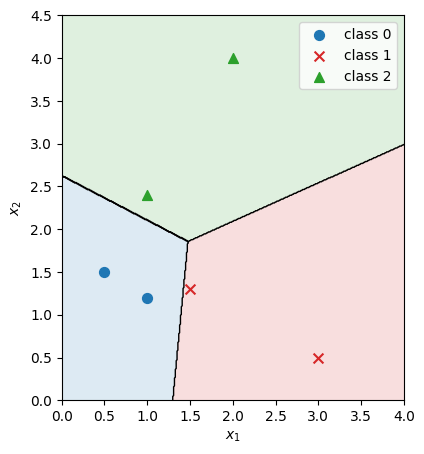

In [7]:
markers, colours = ['o', 'x', '^'], ['tab:blue', 'tab:red', 'tab:green']

def plot_classes(X, y, names, ax=None):
    ax = plt.gca() if ax is None else ax
    for k, name in enumerate(names):
        ax.scatter(X[y == k, 0], X[y == k, 1], marker=markers[k], color=colours[k], s=50, label=name)

def plot_regions(predict_fn, xlim, ylim, ax=None):
    ax = plt.gca() if ax is None else ax
    g1, g2 = np.meshgrid(np.linspace(*xlim, 400), np.linspace(*ylim, 400))
    regions = predict_fn(np.column_stack([g1.ravel(), g2.ravel()])).reshape(g1.shape)
    ax.contourf(g1, g2, regions, levels=[-0.5, 0.5, 1.5, 2.5], colors=colours, alpha=0.15)
    ax.contour(g1, g2, regions, levels=[0.5, 1.5], colors='k', linewidths=1)

plt.figure(figsize=(5, 5))
plot_regions(toy_model.predict, (0, 4), (0, 4.5))
plot_classes(X_toy, y_toy, ['class 0', 'class 1', 'class 2'])
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.legend()
plt.gca().set_aspect('equal')
plt.show()

## Training: the cross-entropy loss

### One-hot encoding

We write each label as a vector of length $K$ with a single $1$, its **one-hot encoding**: with $K = 3$, the label $y = 2$ becomes $(0, 1, 0)$. Entry $k$ is $\delta_{k, y}$, which is $1$ if $k = y$ and $0$ otherwise. The model's probabilities $\mathbf p = (p_1, \dots, p_K)$ form a vector of the same length, and training should make $\mathbf p$ close to the one-hot vector.

In [8]:
def one_hot(y, K):
    """One-hot encoding of the labels y (0, ..., K-1): row i is the unit vector for class y[i]."""
    return np.eye(K)[y]

print(one_hot(y_toy, K))

[[1. 0. 0.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 0. 1.]]


### The cross-entropy cost

The cost of softmax regression is the **cross-entropy**
$$
J(\mathbf W, \mathbf b) = -\frac1m\sum_{i=1}^{m}\sum_{k=1}^{K}\delta_{k, y^{(i)}}\log p_k^{(i)} = -\frac1m\sum_{i=1}^{m}\log p_{y^{(i)}}^{(i)} .
$$
For each example, only one term of the inner sum survives: **minus the log-probability of the true class**. This is the idea of the logistic loss (Lab 8), and for $K = 2$ the cross-entropy is exactly the logistic cost. For the lecture's example $\mathbf p = (0.659, 0.242, 0.099)$:

In [9]:
p = np.array([0.659, 0.242, 0.099])        # = softmax(2, 1, 0.1), rounded
for k in range(K):
    print(f"true class {k + 1}: loss -log p = {-np.log(p[k]):.2f}")

true class 1: loss -log p = 0.42
true class 2: loss -log p = 1.42
true class 3: loss -log p = 2.31


The loss is small when the model gives the true class a large probability, and large when it gives it only $10\%$. To compute the cost stably, we take the logarithm of the softmax directly: $\log p_k = z_k - \log\sum_l e^{z_l}$, again after subtracting the largest score.

In [10]:
def compute_cost(X, y, W, b):
    """Cross-entropy cost of softmax regression, computed from the log-probabilities."""
    Z = X @ W.T + b
    Z = Z - Z.max(axis=1, keepdims=True)
    log_P = Z - np.log(np.exp(Z).sum(axis=1, keepdims=True))      # log softmax, shape (m, K)
    return -np.mean(log_P[np.arange(len(y)), y])                   # log p of the true class

print(f"J(0, 0) = {compute_cost(X_toy, y_toy, np.zeros((K, 2)), np.zeros(K)):.4f}, log 3 = {np.log(3):.4f}")

J(0, 0) = 1.0986, log 3 = 1.0986


With all parameters zero, every class has probability $1/3$, so $J = \log 3$: a useful check.

### The gradient

For one example, the derivative of the loss with respect to the score $z_k$ is $\partial L/\partial z_k = p_k - \delta_{k, y}$: predicted probability minus one-hot label, the **error**. With $\partial z_k/\partial w_{kj} = x_j$ and $\partial z_k/\partial b_k = 1$, averaging over the examples gives
$$
\frac{\partial J}{\partial w_{kj}} = \frac1m\sum_{i=1}^{m}\big(p_k^{(i)} - \delta_{k, y^{(i)}}\big)\,x_j^{(i)},
\qquad
\frac{\partial J}{\partial b_k} = \frac1m\sum_{i=1}^{m}\big(p_k^{(i)} - \delta_{k, y^{(i)}}\big).
$$
Once again: error times input. In matrix form, with the probabilities $\mathbf P$ and the one-hot labels $\mathbf Y$ (both of shape $(m, K)$), $\nabla_{\mathbf W}J = \frac1m(\mathbf P - \mathbf Y)^{\top}\mathbf X$.

In [11]:
def compute_gradient(X, y, W, b):
    """Gradient of the cross-entropy cost: dJ/dW (shape (K, n)) and dJ/db (shape (K,))."""
    E = predict_proba(X, W, b) - one_hot(y, W.shape[0])      # errors P - Y, shape (m, K)
    return E.T @ X / len(y), E.mean(axis=0)

# check against central finite differences at random parameters
rng = np.random.default_rng(0)
W_test, b_test = rng.normal(size=(K, 2)), rng.normal(size=K)
dJ_dW, _ = compute_gradient(X_toy, y_toy, W_test, b_test)
eps, dJ_dW_fd = 1e-6, np.zeros((K, 2))
for k in range(K):
    for j in range(2):
        E_kj = np.zeros((K, 2))
        E_kj[k, j] = eps
        dJ_dW_fd[k, j] = (compute_cost(X_toy, y_toy, W_test + E_kj, b_test)
                          - compute_cost(X_toy, y_toy, W_test - E_kj, b_test)) / (2 * eps)
print(f"largest difference in dJ/dW: {np.max(np.abs(dJ_dW - dJ_dW_fd)):.1e}")

largest difference in dJ/dW: 8.6e-11


### Gradient descent

This is the lecture's gradient descent. It contains one extra term, `lam / m * W`, in the update of $\mathbf W$. This term is the **regularisation** that scikit-learn applies by default, with $\lambda = 1/C = 1$ (Lecture 4 explains it). With it, our result should match scikit-learn's default model.

In [12]:
def gradient_descent(X, y, K, lam=1.0, alpha=0.5, n_iters=20000):
    """Gradient descent for softmax regression from W = 0, b = 0; lam is the regularisation strength."""
    m, n = X.shape
    W, b = np.zeros((K, n)), np.zeros(K)
    Y = one_hot(y, K)                         # (m, K)
    for _ in range(n_iters):
        P = softmax(X @ W.T + b)              # (m, K) probabilities
        E = P - Y                             # (m, K) errors
        W = W - alpha * (E.T @ X / m + lam / m * W)
        b = b - alpha * E.mean(axis=0)
    return W, b

W_gd, b_gd = gradient_descent(X_toy, y_toy, K)
print(f"W =\n{W_gd}\nb = {b_gd}")
print(f"largest difference from scikit-learn: W {np.max(np.abs(W_gd - toy_model.coef_)):.1e}, "
      f"b {np.max(np.abs(b_gd - toy_model.intercept_)):.1e}")

W =
[[-0.639 -0.376]
 [ 0.627 -0.497]
 [ 0.012  0.873]]
b = [ 1.641 -0.002 -1.64 ]
largest difference from scikit-learn: W 2.8e-05, b 6.8e-05


Our gradient descent reproduces scikit-learn's parameters.

::: {.callout-note title="Why include regularisation here?"}
The six examples are perfectly separable. As in Lab 9, the cost without regularisation then has no minimum, and the weights would grow without bound. Moreover, since only differences between the scores matter, many parameter sets give the same probabilities. Regularisation picks one of them: the one with the smallest weights.
:::

## Real data: the iris flowers

The iris data set contains $150$ flowers of three species (setosa, versicolor and virginica), collected by Edgar Anderson and made famous by R. A. Fisher (1936). As in the lecture, we use two features, the petal length and the petal width, and keep $30\%$ of the flowers as a test set.

test accuracy: 0.978


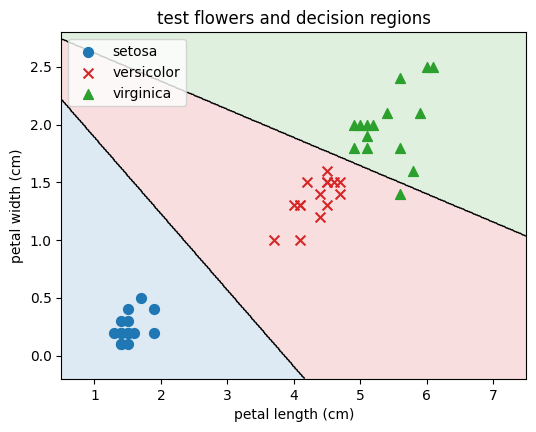

In [13]:
iris = load_iris()
X, y = iris.data[:, 2:], iris.target             # petal length and width (cm); species 0, 1, 2
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

iris_model = make_pipeline(StandardScaler(), LogisticRegression())
iris_model.fit(X_tr, y_tr)
print(f"test accuracy: {iris_model.score(X_te, y_te):.3f}")

plt.figure(figsize=(6, 4.5))
plot_regions(iris_model.predict, (0.5, 7.5), (-0.2, 2.8))
plot_classes(X_te, y_te, iris.target_names)
plt.xlabel('petal length (cm)')
plt.ylabel('petal width (cm)')
plt.title('test flowers and decision regions')
plt.legend(loc='upper left')
plt.show()

Softmax regression divides the plane into three convex regions with straight borders and classifies $97.8\%$ of the test flowers correctly. Our gradient descent, run on the scaled training data, gives the same parameters up to small differences (it stops after a fixed number of iterations):

In [14]:
X_tr_scaled = iris_model[0].transform(X_tr)       # the pipeline's fitted StandardScaler
W_iris, b_iris = gradient_descent(X_tr_scaled, y_tr, K)
print(f"largest difference from scikit-learn: W {np.max(np.abs(W_iris - iris_model[-1].coef_)):.3f}, "
      f"b {np.max(np.abs(b_iris - iris_model[-1].intercept_)):.3f}")

largest difference from scikit-learn: W 0.003, b 0.002


### Evaluating: the confusion matrix

With several classes, the accuracy alone hides **which** classes are confused. The **confusion matrix** counts, in entry $(i, j)$, the test examples of true class $i$ that were predicted as class $j$.

[[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]


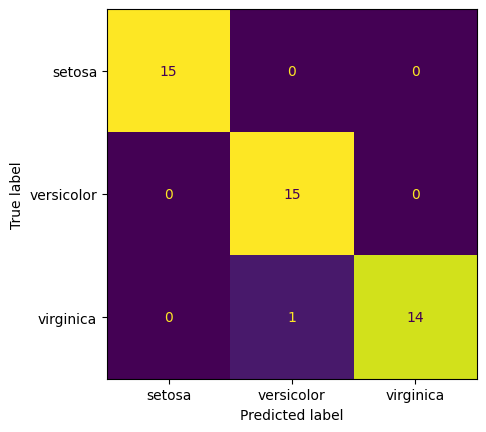

In [15]:
y_pred = iris_model.predict(X_te)
print(confusion_matrix(y_te, y_pred))
ConfusionMatrixDisplay.from_predictions(y_te, y_pred, display_labels=iris.target_names, colorbar=False)
plt.show()

The diagonal holds the correct predictions: $15 + 15 + 14 = 44$ of $45$, i.e. an accuracy of $97.8\%$. The single off-diagonal entry shows that one virginica was predicted as versicolor. Setosa is never confused with another species.

## An alternative: one-vs-rest

Another way to handle $K$ classes is to train $K$ separate **binary** classifiers, each for "class $k$" against "all other classes", and to predict the class whose classifier is most confident. This **one-vs-rest** approach works with any binary classifier:

In [16]:
ovr_model = make_pipeline(StandardScaler(), OneVsRestClassifier(LogisticRegression()))
ovr_model.fit(X_tr, y_tr)
print(f"one-vs-rest test accuracy: {ovr_model.score(X_te, y_te):.3f}")

one-vs-rest test accuracy: 0.978


Here both approaches reach the same accuracy. The difference is that softmax regression trains a single model whose probabilities are consistent and sum to one, whereas one-vs-rest combines $K$ independent models.

## Challenges

1. Compute $\operatorname{softmax}(1, 1, 1)$. Which class does `np.argmax` predict?
2. How many parameters does softmax regression have for $n = 4$ features and $K = 3$ classes? Check your answer by fitting `LogisticRegression` to all four iris features and counting the entries of `coef_` and `intercept_`.
3. A model gives $\mathbf p = (0.7, 0.2, 0.1)$ and the true class is $y = 2$. What is the loss for this example?
4. In a confusion matrix of animal images, row "cat", column "dog" contains $5$. What does this mean?
5. Run `gradient_descent` on the six toy examples with `lam=0` for $2\,000$, $20\,000$ and $200\,000$ iterations. What happens to the weights, and why?

## Summary

- Multiclass classification: $y \in \{1, \dots, K\}$; the model outputs a probability distribution over the $K$ classes and predicts the most probable class.
- Softmax: $\operatorname{softmax}(\mathbf z)_k = e^{z_k}/\sum_l e^{z_l}$; subtract the largest score before exponentiating.
- Softmax regression: one score per class, $z_k = \mathbf w_k\cdot\mathbf x + b_k$, with $K(n + 1)$ parameters. For $K = 2$ it is logistic regression.
- Decision regions are convex, with straight borders.
- Cross-entropy cost: $J = -\frac1m\sum_i\log p^{(i)}_{y^{(i)}}$; gradient $\frac1m(\mathbf P - \mathbf Y)^{\top}\mathbf X$, again error times input.
- scikit-learn: `LogisticRegression` uses softmax automatically for $K > 2$; evaluate with the accuracy and the confusion matrix.